

```
# Bu, kod olarak biçimlendirilmiştir
```

# Araştırma Yöntem ve Teknikleri| 7. Hafta
## Iris veri setiyle makine öğrenmesine ilk adım

**Öğrenci uygulaması — baştan sona açıklamalı.** Bu çalışma ilk makine öğrenmesi deneyiminizdir. Amaç bir çiçeğin **dört sayısal ölçümünden** üç Iris türünden hangisine ait olduğunu tahmin etmektir. **Çiçek fotoğrafı modelin girdisi değildir.**

**Bu notebook sonunda:** CSV okuyacak, tablonun yapısını kontrol edecek, iki grafik oluşturacak, veriyi eğitim/test olarak ayıracak, karar ağacı eğitecek, doğruluk ve karışıklık matrisi hesaplayacak, yeni ölçümden tür tahmin edeceksiniz.

**Çalışma düzeni:** Hücreleri sırayla çalıştırın (`Shift+Enter`). Her hücrenin üzerindeki açıklamayı okuyun. Son bölümdeki `TODO` görevlerini **kendiniz** tamamlayın. GitHub'a yükleme istenmiyor.

## 1. Veri setini tanıyalım
**Iris** üç çiçek türüne ilişkin kayıtlar içerir: *setosa*, *versicolor*, *virginica*. Toplam **150 satır**, her türde **50** örnek, her satırda **4 ölçüm (cm)** vardır.

| Ölçüm | İngilizce adı | Anlamı |
|---|---|---|
| `sepal_length_cm` | sepal length | Çanak yaprağın uzunluğu |
| `sepal_width_cm` | sepal width | Çanak yaprağın genişliği |
| `petal_length_cm` | petal length | Taç yaprağın uzunluğu |
| `petal_width_cm` | petal width | Taç yaprağın genişliği |

`species` sütunu **etiket (target)** alanıdır. Örneğin `versicolor` bir sayı değil sınıf adıdır. **Bir satır = bir çiçeğin ölçüm kaydı.**

Veri kaynağı: UCI Iris (DOI: https://doi.org/10.24432/C56C76, CC BY 4.0). Ayrıca çalışma için Kaggle yansıması: https://www.kaggle.com/datasets/uciml/iris

## 2. Kaggle'dan indirme ve Colab'a yükleme (isteğe bağlı)
1. [Kaggle Iris Species](https://www.kaggle.com/datasets/uciml/iris) sayfasını açın; **lisans** ve veri açıklamasını inceleyin.
2. **Download** ile ZIP dosyasını indirin; içindeki `Iris.csv` dosyasını çıkarın.
3. Notebook'un **4. bölümündeki tek kod hücresini** çalıştırın. `CSV_YUKLE = True` iken **Choose Files / Dosya Seç** penceresi açılır. CSV dosyanızı seçtiğinizde kod **aynı hücrede** dosyayı okur ve ilk 5 satırı gösterir. **İkinci bir yükleme/okuma hücresi çalıştırmanız gerekmez.**
4. CSV kullanmak istemiyorsanız aynı hücrede `CSV_YUKLE = False` yapın. Böylece dosya seçme penceresi açılmaz, `scikit-learn` içindeki hazır Iris veri seti kullanılır. İki veri dağıtımı arasında bazı kayıt farklılıkları olabilir. Raporunuzda veri kaynağını belirtin.

**Alternatif:** CSV'yi Colab'ın solundaki **Files / Dosyalar** panelinden `Iris.csv` adıyla yükleyebilirsiniz. Sonrasında aynı yükleme hücresini çalıştırıp Choose Files penceresini iptal ederseniz, kod panelden yüklenmiş `Iris.csv` dosyasını kullanmayı dener.

**Önemli:** Tek hücreyi tekrar çalıştırırsanız dosya seçme penceresi **yeniden açılır**, CSV tekrar okunur ve `veri` tablosunun üzerine yazılır; satırlar iki kez eklenmez. Aynı dosyayı yeniden yüklerseniz Colab dosyaya farklı bir ad verebilir. Çalışma ortamı sıfırlanınca dosyayı yeniden yüklemeniz gerekir.

**Güvenlik:** Kaggle API anahtarı, parola veya erişim belirteci paylaşmayın. Bu çalışma API anahtarı gerektirmez. Dışarıya kişisel bilgi yüklemeyin.


## 3. Kütüphane nedir, `import` neden yazılır?
Bir **kütüphane**, başkalarının geliştirdiği ve tekrar kullanabildiğimiz programlama araçlarıdır. `import` ifadesi bu araçları kullanmak için çalışma ortamına ekler.

- `pandas`: CSV dosyasını tabloya dönüştürür.
- `matplotlib.pyplot`: grafik oluşturur.
- `scikit-learn` (`sklearn`): hazır makine öğrenmesi algoritmaları ve değerlendirme araçları sunar.
- `Path`: dosyanın bulunup bulunmadığını kontrol eder.

`as pd` yazmak, `pandas` yerine kısa `pd` takma adını kullanacağımız anlamına gelir.

In [1]:
from pathlib import Path                  # Dosya yoluyla işlem yapar
import pandas as pd                         # Tablo ve CSV işlemleri
import matplotlib.pyplot as plt            # Grafik çizimi
from sklearn.datasets import load_iris     # Hazır Iris veri seti

print("Kütüphaneler hazır.")

Kütüphaneler hazır.


## 4. Veri setini tek hücrede seçelim ve okuyalım
Aşağıdaki **tek hücre**, dosya seçme ve CSV'yi tabloya dönüştürme işlemlerini birlikte yapar. Başka bir okuma hücresi çalıştırmanız gerekmez.

- **`CSV_YUKLE = True`:** `Choose Files / Dosya Seç` açılır. `Iris.csv` dosyanızı seçin. Seçmezseniz kod çalışma klasöründeki `Iris.csv` / `iris.csv` dosyasına bakar; o da yoksa hazır veriyi kullanır.
- **`CSV_YUKLE = False`:** Hiç dosya sormadan `scikit-learn` içindeki hazır Iris veri setini kullanır.

**Önemli terimler**
- **CSV:** Virgülle ayrılmış değerleri saklayan düz metin dosyası.
- **DataFrame:** Satır ve sütunlardan oluşan pandas tablosu.
- **`pd.read_csv()`:** CSV'yi DataFrame'e dönüştürür.
- **`if` / `else`:** Hangi veri kaynağının kullanılacağını koşula göre belirler.
- **`rename`:** Sütun adlarını iki kaynakta da ortak hâle getirir.
- **`head(5)`:** Tablonun ilk beş satırını gösterir.


### Dosya seçme ve okuma — tek kod hücresi
**Öğrencinin yapacağı işlem:** Alttaki kodu çalıştırın, açılan pencereden `Iris.csv` seçin. Hücre yükleme, okuma ve ilk 5 satırı görüntüleme işlemlerini **tek seferde** tamamlar. Hazır veri setini kullanmak isteyenler `CSV_YUKLE = False` yapmalıdır.


In [2]:
# VERİ KAYNAĞI SEÇİMİ
CSV_YUKLE = False  # True: Choose Files ile CSV seç; False: hazır Iris veri seti

csv_yolu = None

if CSV_YUKLE:
    try:
        from google.colab import files
        yuklenen = files.upload()  # Choose Files / Dosya Seç penceresini açar
        csv_dosyalari = [ad for ad in yuklenen if ad.lower().endswith(".csv")]
        if csv_dosyalari:
            csv_yolu = Path(csv_dosyalari[0])
    except ImportError:
        print("Choose Files yalnızca Google Colab'da çalışır; mevcut CSV aranacak.")

    # Dosya seçilmediyse sol panelden yüklenmiş dosyayı ara.
    if csv_yolu is None:
        csv_yolu = next(
            (Path(ad) for ad in ("Iris.csv", "iris.csv") if Path(ad).is_file()),
            None
        )

if csv_yolu is not None:
    # CSV dosyasını pandas DataFrame'e dönüştür.
    veri = pd.read_csv(csv_yolu)
    veri = veri.rename(columns={
        "SepalLengthCm": "sepal_length_cm",
        "SepalWidthCm": "sepal_width_cm",
        "PetalLengthCm": "petal_length_cm",
        "PetalWidthCm": "petal_width_cm",
        "Species": "species"
    })
    veri = veri.drop(columns=["Id"], errors="ignore")
    if "species" not in veri.columns:
        raise ValueError("CSV dosyasında Species/species sütunu yok. Iris.csv seçin.")
    veri["species"] = veri["species"].str.replace("Iris-", "", regex=False).str.lower()
    kaynak = f"Yüklenen CSV dosyası: {csv_yolu.name}"
else:
    # Hazır Iris veri setini DataFrame'e dönüştür.
    iris = load_iris(as_frame=True)
    veri = iris.frame.rename(columns={
        "sepal length (cm)": "sepal_length_cm",
        "sepal width (cm)": "sepal_width_cm",
        "petal length (cm)": "petal_length_cm",
        "petal width (cm)": "petal_width_cm"
    })
    veri["species"] = veri["target"].map(dict(enumerate(iris.target_names)))
    veri = veri.drop(columns=["target"])
    kaynak = "scikit-learn yerleşik Iris veri seti"

print("Veri kaynağı:", kaynak)
print("Tablo boyutu:", veri.shape)
display(veri.head(5))  # İlk 5 satırı hemen göster.


Veri kaynağı: scikit-learn yerleşik Iris veri seti
Tablo boyutu: (150, 5)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


**Kodun ayrıntısı:** `CSV_YUKLE` veri kaynağını belirler. `files.upload()` dosya seçme penceresini açar; `pd.read_csv()` seçilen dosyadan tablo oluşturur. `Path(...).is_file()` dosyanın varlığını kontrol eder. `drop(..., errors="ignore")`, `Id` sütunu varsa siler, yoksa hata vermez. `.map()` sayısal sınıf kodlarını tür adlarına dönüştürür. `.shape`, (satır sayısı, sütun sayısı) bilgisini verir. Beklenen boyut **(150, 5)**. Bu kod hücresi tekrar çalıştırıldığında `veri` değişkeni yeniden oluşturulur; satırlar üst üste eklenmez.


## 5. İlk kayıtları ve sütunları inceleme
`head(n)` ilk `n` satırı; `columns` sütun adlarını; `shape` tablonun boyutunu gösterir. `print` ekrana metin veya değer yazdırır. Böylece **modeli eğitmeden önce** verinin gerçekten beklediğimiz biçimde geldiğini denetleriz.

In [3]:
print("Sütunlar:", veri.columns.tolist())
print("Boyut:", veri.shape)
display(veri.head(5))

Sütunlar: ['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm', 'species']
Boyut: (150, 5)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 6. Veri kalitesi: eksik alan, tip ve sınıf dağılımı
Makine öğrenmesinde yanlış veri, modelin öğrendiği ilişkileri bozabilir. `info()` her sütunun veri tipini; `isna().sum()` boş alan sayısını; `value_counts()` türlerin kaç kez geçtiğini gösterir. Bu Iris dağıtımında eksik değer beklenmez, ancak **her projede kontrol yapılmalıdır.**

In [4]:
veri.info()
print("\nEksik değer sayıları:\n", veri.isna().sum())
print("\nTürlere göre gözlem sayısı:\n", veri["species"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sepal_length_cm  150 non-null    float64
 1   sepal_width_cm   150 non-null    float64
 2   petal_length_cm  150 non-null    float64
 3   petal_width_cm   150 non-null    float64
 4   species          150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Eksik değer sayıları:
 sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species            0
dtype: int64

Türlere göre gözlem sayısı:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 7. Sayısal özet: ortalama, en küçük, en büyük
`describe()` sayısal sütunların sayısını (`count`), ortalamasını (`mean`), standart sapmasını (`std`), en küçük ve en büyük değerlerini listeler. Ortalama bütün gözlemleri özetler; ancak türler arasındaki farkları tek başına açıklamaz.

In [5]:
display(veri.describe().round(2))
ortalama = veri.groupby("species")["petal_length_cm"].mean()
print("Tür bazında ortalama taç yaprak uzunluğu (cm):")
print(ortalama.round(2))

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


Tür bazında ortalama taç yaprak uzunluğu (cm):
species
setosa        1.46
versicolor    4.26
virginica     5.55
Name: petal_length_cm, dtype: float64


**`groupby` ifadesini okuyalım:** `veri.groupby("species")` tabloyu türlere göre gruplar. `["petal_length_cm"]` yalnızca bir ölçümü seçer. `.mean()` her grubun ortalamasını alır. `.round(2)` sonucu iki ondalık basamağa yuvarlar. Bu işlem **model eğitimi değildir**, veri analizidir.

## 8. Görselleştirme: nokta grafiği
Grafikte her **nokta bir çiçektir**. Yatay eksen taç yaprak uzunluğunu, dikey eksen taç yaprak genişliğini, renkler gerçek türü gösterir. Aynı türün noktaları yakın kümeleniyorsa bu ölçümler türleri ayırmak için bilgi taşıyabilir. **Grafik ilişkiyi gösterir; tahmin yapmaz.**

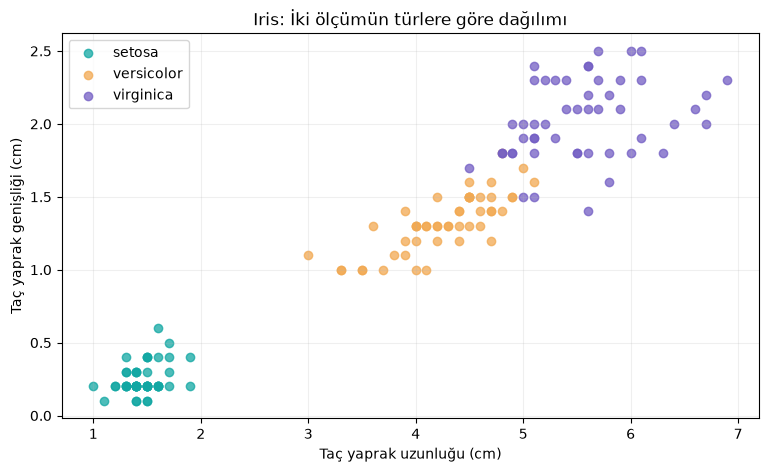

In [6]:
renkler = {"setosa": "#12a7a3", "versicolor": "#f2a952", "virginica": "#735ec4"}
plt.figure(figsize=(9, 5))
for tur, grup in veri.groupby("species"):
    plt.scatter(grup["petal_length_cm"], grup["petal_width_cm"],
                label=tur, alpha=0.75, color=renkler[tur])
plt.xlabel("Taç yaprak uzunluğu (cm)")
plt.ylabel("Taç yaprak genişliği (cm)")
plt.title("Iris: İki ölçümün türlere göre dağılımı")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

**Satır satır:** `figure` yeni bir grafik alanı açar. `for`, üç türü sırayla dolaşır. `plt.scatter(x, y)` iki sayısal değişkeni noktalarla çizer. `label` açıklama kutusundaki tür adıdır. `alpha=0.75` noktaları biraz saydam yapar. `xlabel` ve `ylabel` eksen adlarıdır. `legend()` tür açıklamasını ekler. `show()` çizimi görüntüler.

## 9. Makine öğrenmesi: dört temel kavram
**Özellik (feature):** Bir çiçeğin `sepal_length_cm` gibi ölçümüdür. **Etiket (target):** Tahmin edilmek istenen gerçek türdür. **Denetimli öğrenme:** Eğitim sırasında hem ölçüm hem doğru tür bilinir. **Model:** Bu örneklerden bir karar verme kuralı çıkaran algoritmanın eğitilmiş hâlidir.

Bu örnekte özellik tablosu `X`, etiket dizisi `y` olacaktır. Python **büyük/küçük harfe duyarlıdır**: `X` ile `x` farklı isimlerdir.

In [7]:
ozellikler = ["sepal_length_cm", "sepal_width_cm",
             "petal_length_cm", "petal_width_cm"]
X = veri[ozellikler]          # Modelin girdi tablosu: 150 x 4
y = veri["species"]          # Modelin tahmin etmeyi öğreneceği tür

print("X boyutu:", X.shape)
print("y boyutu:", y.shape)
display(X.head(3))

X boyutu: (150, 4)
y boyutu: (150,)


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


## 10. Neden eğitim/test ayrımı yaparız?
Modeli **sınavda hiç görmediği örneklerle** değerlendirmek gerekir. Tüm 150 çiçek üzerinde öğrenip aynı 150 çiçek üzerinde başarı hesaplamak, genelleme yeteneğini güvenilir biçimde ölçmez.

- **Eğitim kümesi:** Kuralın öğrenildiği kayıtlar.
- **Test kümesi:** Eğitimde kullanılmayan, sonradan değerlendirilen kayıtlar.
- `test_size=0.20`: verinin %20'si test için ayrılır (bu veri kümesinde 30 kayıt).
- `random_state=42`: rastgele bölmeyi tekrarlanabilir yapar; başarıyı otomatik olarak iyileştirmez.
- `stratify=y`: üç türün oranlarını eğitim ve testte yaklaşık aynı tutar.

In [8]:
from sklearn.model_selection import train_test_split

X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Eğitim örnekleri:", len(X_egitim))
print("Test örnekleri:", len(X_test))
print("Eğitimde tür dağılımı:\n", y_egitim.value_counts())
print("Testte tür dağılımı:\n", y_test.value_counts())

Eğitim örnekleri: 120
Test örnekleri: 30
Eğitimde tür dağılımı:
 species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64
Testte tür dağılımı:
 species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## 11. Karar ağacı (Decision Tree) nedir?
Karar ağacı, ölçümleri kullanarak “Taç yaprak genişliği belirli bir eşikten küçük mü?” gibi sorularla dallara ayrılan bir **sınıflandırma algoritmasıdır**. Bu örnekte ağaç, hangi soruların işe yaradığını **eğitim verisinden öğrenir**.

- **Düğüm (node):** Ölçüm koşulunun sınandığı yer.
- **Dal (branch):** Koşulun doğru/yanlış sonucuyla izlenen yol.
- **Yaprak (leaf):** Son tür tahmininin üretildiği yer.
- `max_depth=3`: ağacın derinliğini sınırlar; aşırı ezberlemeyi azaltmaya yardımcı olabilir.

Bu ilk uygulamada **StandardScaler, one-hot encoding veya yapay sinir ağı gerekmez**: karar ağacı doğrudan sayısal ölçümler ve tür adlarıyla çalışabilir.

In [9]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_egitim, y_egitim)
print("Karar ağacı eğitildi.")

Karar ağacı eğitildi.


**Satır satır:** `DecisionTreeClassifier(...)` henüz eğitilmemiş bir sınıflandırıcı nesnesi oluşturur. `max_depth` bir model ayarıdır (**hiperparametre**). `model.fit(X_egitim, y_egitim)` ise gerçek **öğrenme/eğitim** işlemini başlatır. Bu örnekte öğrenci modelin kurallarını tek tek kodlamaz; algoritma veriden uygun eşikleri seçer.

## 12. Tahmin (prediction) ve değerlendirme
`predict(X_test)`, modelin daha önce görmediği 30 çiçek için tür tahminidir. `accuracy_score`, doğru tahmin sayısını toplam test sayısına bölerek **doğruluk** hesaplar. Örneğin 29 doğru / 30 test = 0.9667 ≈ %96.7. Gerçek oran, kullanılan veri dağıtımına ve ayarlara göre farklı olabilir.

In [10]:
from sklearn.metrics import accuracy_score

y_tahmin = model.predict(X_test)
dogruluk = accuracy_score(y_test, y_tahmin)
print("Test doğruluğu: %{:.1f}".format(dogruluk * 100))
print("İlk 5 tahmin:", y_tahmin[:5].tolist())
print("İlk 5 gerçek tür:", y_test.iloc[:5].tolist())

Test doğruluğu: %96.7
İlk 5 tahmin: [np.str_('setosa'), np.str_('virginica'), np.str_('versicolor'), np.str_('versicolor'), np.str_('setosa')]
İlk 5 gerçek tür: [np.str_('setosa'), np.str_('virginica'), np.str_('versicolor'), np.str_('versicolor'), np.str_('setosa')]


## 13. Karışıklık matrisi (Confusion Matrix)
Tek bir doğruluk yüzdesi, **hangi türlerin karıştırıldığını** göstermez. Karışıklık matrisi bu ayrıntıyı verir. **Satırlar gerçek türleri, sütunlar tahmin edilen türleri** gösterir. Köşegen üzerindeki hücreler doğru, köşegen dışındaki hücreler yanlış sınıflandırmaları belirtir.

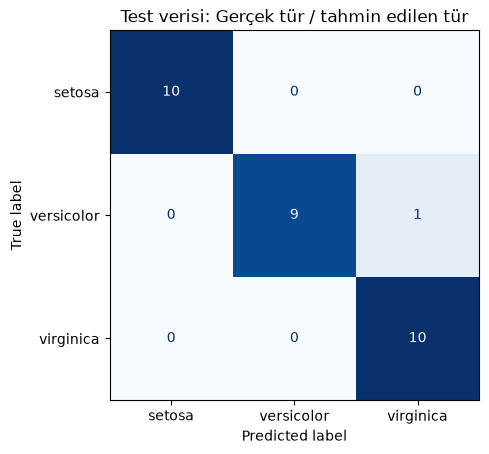

[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

turler = ["setosa", "versicolor", "virginica"]
matris = confusion_matrix(y_test, y_tahmin, labels=turler)
gosterim = ConfusionMatrixDisplay(matris, display_labels=turler)
gosterim.plot(cmap="Blues", colorbar=False)
plt.title("Test verisi: Gerçek tür / tahmin edilen tür")
plt.show()
print(matris)

## 14. Ağacın öğrendiği kuralları görselleştirelim
`plot_tree` eğitilen modelin koşullarını bir şema hâlinde gösterir. `feature_names`, değişken isimlerini, `class_names` tür isimlerini, `filled=True` ise düğümlerin renkli gösterilmesini sağlar. **Not:** Ağaç sadece **eğitim verisi** üzerinde öğrenmiştir; bu şema tek başına başarı kanıtı değildir.

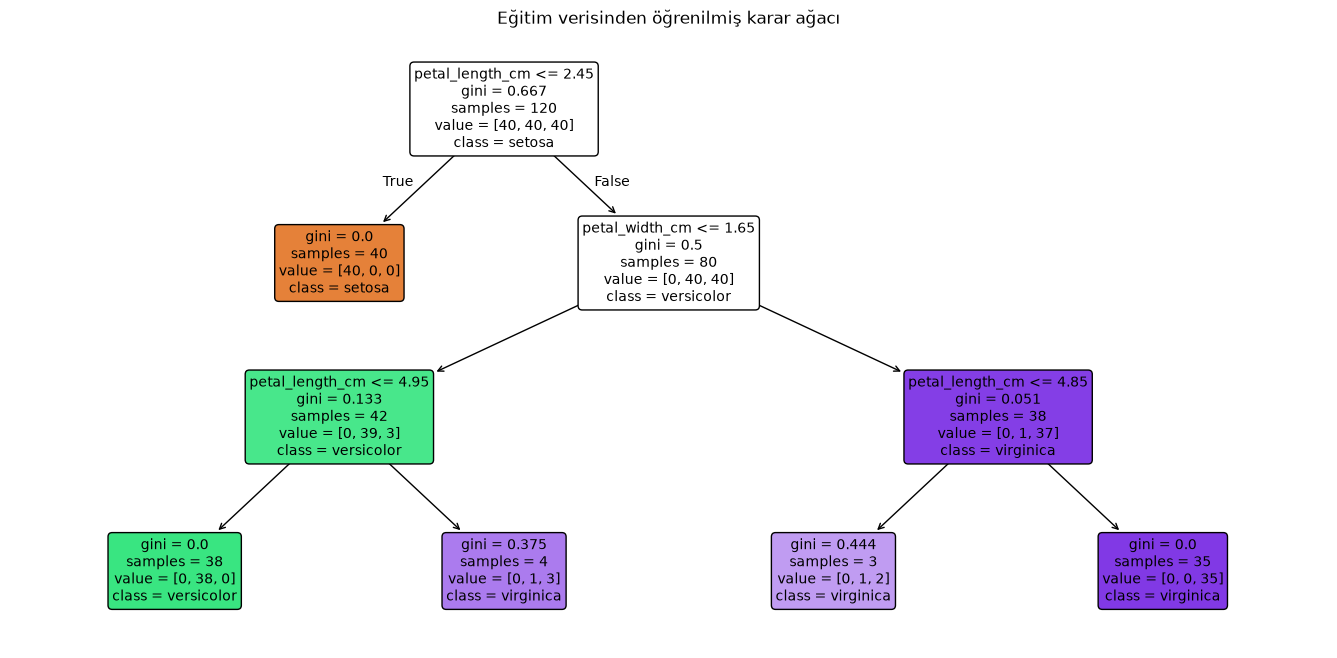

In [12]:
from sklearn.tree import plot_tree

plt.figure(figsize=(17, 8))
plot_tree(model, feature_names=ozellikler,
          class_names=model.classes_, filled=True,
          rounded=True, fontsize=10)
plt.title("Eğitim verisinden öğrenilmiş karar ağacı")
plt.show()

## 15. Yeni bir çiçeğin türünü tahmin etme
Aşağıdaki dört sayı **cm cinsinden varsayımsal bir çiçek ölçümüdür.** Kod bir satırlık yeni bir `DataFrame` oluşturur. Model, eğitimdeki sütun isimleri ve sırasını beklediği için `columns=ozellikler` kullanıyoruz.

Bu tür tahminleri eğitim amaçlıdır; doğadaki tüm Iris türlerini tanıyacak kapsamlı bir botanik sistem değildir.

In [13]:
yeni_cicek = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=ozellikler
)
print("Yeni gözlem:\n", yeni_cicek)
print("Tahmin edilen tür:", model.predict(yeni_cicek)[0])

Yeni gözlem:
    sepal_length_cm  sepal_width_cm  petal_length_cm  petal_width_cm
0              5.1             3.5              1.4             0.2
Tahmin edilen tür: setosa


## 16. Sonuçların raporlanması
Elde edilen sonuç, kullanılan veri kaynağı, bölme oranı, algoritma ve test başarısıyla birlikte raporlanmalıdır. Böylece çalışma **yeniden üretilebilir** olur. JSON, anahtar–değer biçiminde yapılandırılmış veri saklar. CSV ise tablo çıktısı için uygundur.

In [14]:
import json

rapor = {
    "veri_kaynagi": kaynak,
    "egitim_sayisi": len(X_egitim),
    "test_sayisi": len(X_test),
    "algoritma": "DecisionTreeClassifier",
    "max_depth": 3,
    "random_state": 42,
    "test_dogrulugu": round(float(dogruluk), 4)
}
with open("iris_sonuc.json", "w", encoding="utf-8") as dosya:
    json.dump(rapor, dosya, ensure_ascii=False, indent=2)

sonuclar = X_test.copy()
sonuclar["gercek_tur"] = y_test.values
sonuclar["tahmin_tur"] = y_tahmin
sonuclar.to_csv("iris_test_tahminleri.csv", index=False)
print(rapor)
print("Oluşturulan dosyalar: iris_sonuc.json, iris_test_tahminleri.csv")

{'veri_kaynagi': 'scikit-learn yerleşik Iris veri seti', 'egitim_sayisi': 120, 'test_sayisi': 30, 'algoritma': 'DecisionTreeClassifier', 'max_depth': 3, 'random_state': 42, 'test_dogrulugu': 0.9667}
Oluşturulan dosyalar: iris_sonuc.json, iris_test_tahminleri.csv


## 17. Kodla kontrol: `assert` ne işe yarar?
`assert`, belirtilen koşul yanlışsa hata vererek beklediğimiz bir özelliği kontrol eder. `len`, öğe sayısını hesaplar; `set`, tekrarsız değerleri tutar. Bu üç kontrol **temel çalışma doğrulamasıdır**, modelin her durumda güvenilir olduğunu kanıtlamaz.

In [15]:
assert len(veri) == 150, "150 gözlem bekleniyordu."
assert veri["species"].nunique() == 3, "Üç sınıf bekleniyordu."
assert len(X_egitim) + len(X_test) == len(veri), "Veri bölmede eksik olabilir."
print("Temel kontroller başarılı.")

Temel kontroller başarılı.


## Sık karşılaşılan hatalar
- **Dosya seçme sorunu:** `Choose Files` yalnızca Google Colab'da çalışır. İsterseniz Colab sol panelinden `Iris.csv` yükleyebilir veya `CSV_YUKLE = False` ile hazır Iris verisini kullanabilirsiniz.
- **Hücreyi yeniden çalıştırma:** `CSV_YUKLE = True` ise pencere yeniden açılır. Dosya tekrar okunur, satırlar iki kez eklenmez. Aynı dosya yeniden yüklenirse Colab farklı bir ad verebilir.
- **`NameError`:** İlgili değişkeni oluşturan hücre çalıştırılmadı. Üstteki hücrelerden başlayın.
- **`KeyError: 'species'`:** CSV sütun adları normalleştirilemedi; `print(veri.columns)` ile kontrol edin.
- **Şekil farklılığı (`shape`):** Özellik sayısını veya `Id` sütununu yanlışlıkla modele aldınız mı kontrol edin.
- **Yüksek doğruluk = kusursuz model değildir.** Veri kümesi küçüktür; test sonucu bölünmeye bağlı değişebilir.

## Kaynaklar
- UCI Iris: https://archive.ics.uci.edu/dataset/53/iris — CC BY 4.0.
- Kaggle Iris Species: https://www.kaggle.com/datasets/uciml/iris
- scikit-learn kullanıcı kılavuzu: https://scikit-learn.org/stable/supervised_learning.html
- Devreyakan (veri ön işleme ve sinir ağı örneği): https://devreyakan.com/iris-veri-seti-projesi/
- Serkan Karakuş (görselleştirme ve algoritma karşılaştırmaları): https://medium.com/@serkankarakus/iris-veri-seti-%C3%BCzerinde-g%C3%B6rselle%C5%9Ftirme-ve-makine-%C3%B6%C4%9Frenmesi-algoritmalar%C4%B1n%C4%B1n-uygulanmas%C4%B1-7f0c5daf29dd


## Öğrenci notu (TODO / yorum)
**Sonuç:** Karar ağacı (`max_depth=3`) test kümesinde (30 kayıt) yukarıda görülen doğruluğu elde etmiştir. Setosa türü diğerlerinden kolayca ayrılırken hatalar versicolor ve virginica arasında yoğunlaşır; bu iki tür ölçümlerde birbirine yakındır.
**Sınırlılık:** Veri 150 gözlemlik küçük bir öğretim veri setidir; doğruluk rastgele bölmeye bağlıdır ve bu sonuç tüm Iris çiçeklerine genellenmemelidir.
**Veri kaynağı:** UCI Iris, DOI: 10.24432/C56C76, CC BY 4.0.